# Figures 2 and 3: two solvers

This notebook draws Figures 2 and 3 (Section 2) of

> G. Fasano, C. Piermarini, M. Roma. *Benchmarking Optimization Algorithms with Quality Profiles.* Mathematical Programming Computation (accepted), [arXiv:2607.16798](https://arxiv.org/abs/2607.16798).

Each figure uses the same results and the same parameters `r1` and `r2` as the MATLAB script of the [reference repository](https://github.com/fasano-g/Quality-Profiles) that produced it, so the two implementations can be compared side by side. The MATLAB scripts all start with `r1 = 1; r2 = 1;` (line 186): to reproduce a figure with different values, set them there.

| Figure | `r1` | `r2` | MATLAB script |
| --- | --- | --- | --- |
| 2 | 10 | 3 | `Profiles_N_codes_v3_github_revised_Figures_2_3.m` |
| 3 | 4 | 1 | `Profiles_N_codes_v3_github_revised_Figures_2_3.m` |

The results are read from `examples/data` (see [`examples/data/README.md`](../examples/data/README.md)). The colors fade from red to blue as in the paper (`colors="paper"`). The profiles are drawn as step functions, their exact shape; the MATLAB figures join the grid points with straight segments instead, which shows as slanted lines where the grid is sparse. Pass `steps=False` to `draw` to get the same look.

In [13]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt

from quality_profiles import plot_quality_profiles, quality_profiles

# The results of the paper are in examples/data; examples/utils/paper_data.py reads them.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "examples" / "data").is_dir())
sys.path.insert(0, str(ROOT / "examples"))
from utils.paper_data import load  # noqa: E402

plt.rcParams["figure.dpi"] = 110

# Every figure has the size of the default ones: 6.4 x 4 inches at 110 dpi.
FIGSIZE = (6.4, 4.0)
WIDTH, HEIGHT = 716, 452  # pixels, for the Plotly figures


def draw(
    figure, dataset, r1=1, r2=1, n=None, ax=None, legend=True, legend_loc="lower right", steps=True
):
    """Compute and plot the quality profiles of one figure of the paper.

    steps=False joins the grid points with straight segments, as the MATLAB figures do.
    """
    f0, f_solvers, names = load(dataset, n=n)
    qp = quality_profiles(f0, f_solvers, solver_names=names, r1=r1, r2=r2)
    title = f"{figure}: |S| = {len(names)}, |P| = {len(f0)}, r1 = {r1}, r2 = {r2}"
    plot_quality_profiles(
        qp, ax, colors="paper", title=title, legend=legend, legend_loc=legend_loc, steps=steps
    )
    return qp


def table(qp, levels=(1, 1e-1, 1e-3, 1e-6, 1e-9, 1e-12)):
    """Print the profiles at a few precision levels."""
    print(f"{'precision':>10s}" + "".join(f"{name:>14s}" for name in qp.solver_names))
    for level, row in zip(levels, qp.evaluate(levels), strict=True):
        print(f"{level:>10.0e}" + "".join(f"{value:>14.3f}" for value in row))

## Figure 2

Quality profiles of two solvers on 166 test problems, with `r1 = 10` and `r2 = 3`. With `r1 = 10` the abscissa covers 40 orders of magnitude: the smallest precision level sampled is $(10^{-4})^{10} = 10^{-40}$.

In [14]:
qp = draw("Fig. 2", "two_solvers", r1=10, r2=3)
plt.show()

TypeError: plot_quality_profiles() got an unexpected keyword argument 'steps'

## Figure 3

The same solvers with `r1 = 4` and `r2 = 1`. With `r2 = 1` the ordinate is the plain fraction of problems.

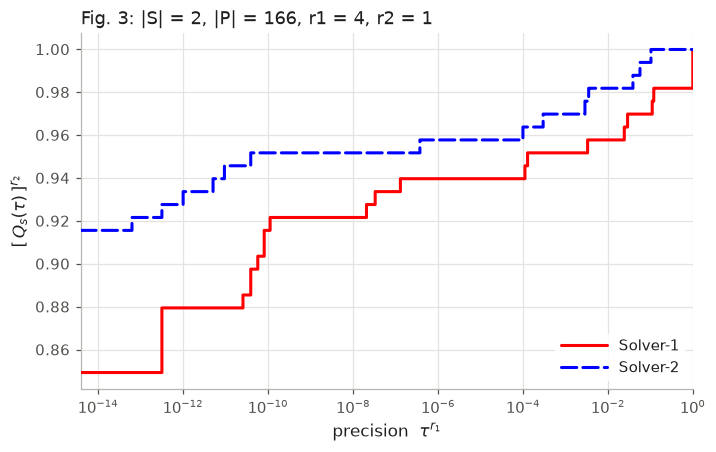

In [ ]:
qp = draw("Fig. 3", "two_solvers", r1=4, r2=1)
plt.show()

## Straight segments, as in the MATLAB figures

The profiles are computed on a grid of precision levels. The MATLAB code joins consecutive grid points with straight segments. On a logarithmic axis the first grid points are far apart, so the segments between them are visibly slanted: in Figure 3 (`r1 = 4`, 4000 intervals) the first two levels are $(1/4000)^4 \approx 4 \cdot 10^{-15}$ and $(2/4000)^4$, sixteen times larger. `steps=False` draws the profiles in the same way. The values at the grid points do not change: the steps show the exact shape of a profile, which only changes by jumps.

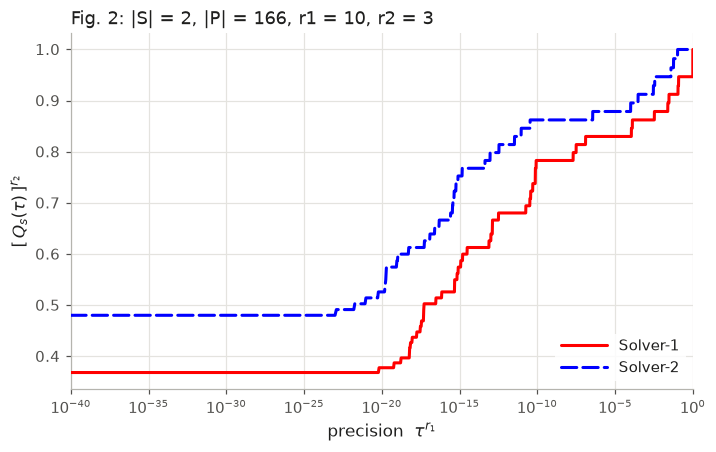

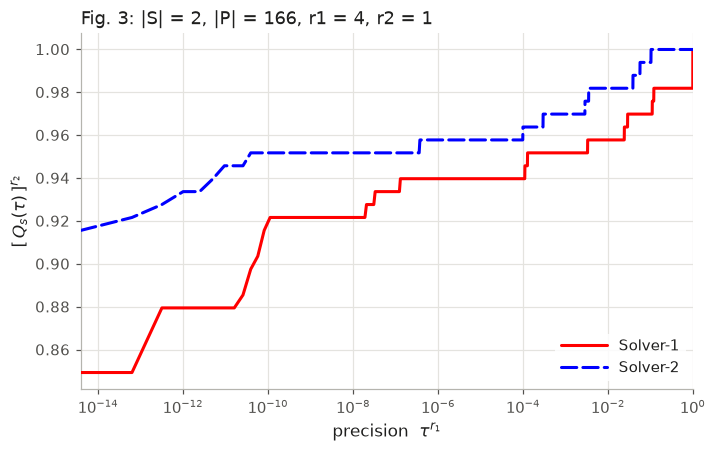

In [ ]:
for figure, r1, r2 in [("Fig. 2", 10, 3), ("Fig. 3", 4, 1)]:
    draw(figure, "two_solvers", r1=r1, r2=r2, steps=False)
    plt.show()

## The same figures with SciencePlots

`style=` accepts any matplotlib style. The SciencePlots style `"science"` sizes the figure for one journal column and uses serif fonts. It needs the optional extra: `pip install "quality-profiles[science]"`.

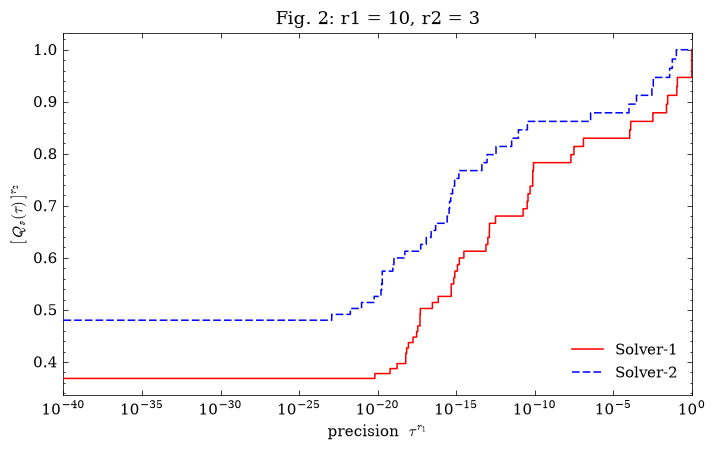

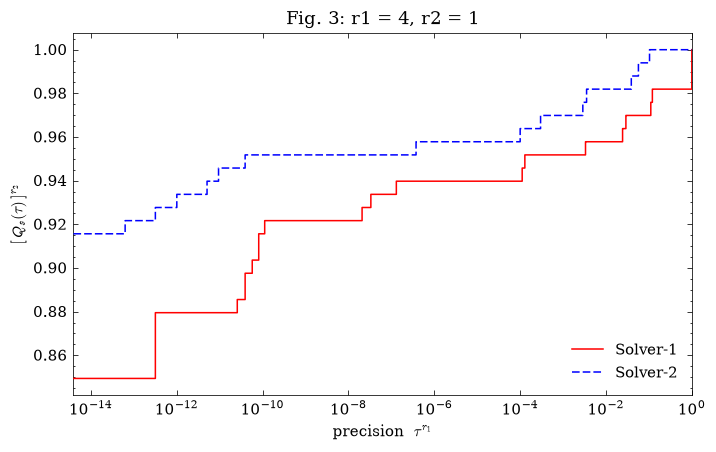

In [ ]:
f0, f_solvers, names = load("two_solvers")

for figure, r1, r2 in [("Fig. 2", 10, 3), ("Fig. 3", 4, 1)]:
    qp = quality_profiles(f0, f_solvers, solver_names=names, r1=r1, r2=r2)
    ax = plot_quality_profiles(
        qp,
        style="science",
        colors="paper",
        title=f"{figure}: r1 = {r1}, r2 = {r2}",
        legend_loc="lower right",
    )
    ax.figure.set_size_inches(FIGSIZE)  # same size as the figures above
    plt.show()

## The same figures as interactive Plotly plots

Drag to zoom, double-click to reset, click a solver in the legend to hide it, and hover to read the value of both solvers at that precision level. The figures show in Jupyter and VS Code, but not in GitHub's static preview of the notebook. They need the optional extra: `pip install "quality-profiles[interactive]"`.

In [ ]:
import plotly.io as pio

from quality_profiles import plot_quality_profiles_interactive

pio.renderers.default = "plotly_mimetype+notebook_connected"

for figure, r1, r2 in [("Fig. 2", 10, 3), ("Fig. 3", 4, 1)]:
    qp = quality_profiles(f0, f_solvers, solver_names=names, r1=r1, r2=r2)
    title = f"{figure}: |S| = {len(names)}, |P| = {len(f0)}, r1 = {r1}, r2 = {r2}"
    plot_quality_profiles_interactive(
        qp, colors="paper", title=title, width=WIDTH, height=HEIGHT
    ).show()

## Values at a few precision levels

At precision $10^{-k}$, the fraction of problems on which each solver reduced $f(x_0) - f_L$ by at least $k$ orders of magnitude (Figure 3, `r2 = 1`):

In [ ]:
table(quality_profiles(f0, f_solvers, solver_names=names, r1=4, r2=1))

 precision      Solver-1      Solver-2
     1e+00         1.000         1.000
     1e-01         0.970         0.994
     1e-03         0.952         0.970
     1e-06         0.940         0.958
     1e-09         0.922         0.952
     1e-12         0.880         0.934
